# 02. 지역 이름 통일(주소 정규화)과 데이터 합치기

**SEMESH for Android · 데이터 분석 2단계** — `02_merge.py`와 같은 작업을 셀 단위로 확인합니다.

01단계에서 발견한 문제: 같은 지역이 파일마다 다르게 적혀 있다.

| | 보증사고 파일 (기준표) | 피해주택 파일 |
|---|---|---|
| 광역시 | `서울` `강서구` | `서울시` `강서구` |
| 일반구가 있는 시 | `경기` `수원장안구` | `수원시` `장안구` (도 이름 없음) |
| 세종 | `세종` `세종시` | `세종시` (시군구 빈칸) |
| 오타 | — | `선안시` `서북구` |

**전략**: 보증사고 파일의 256개 시군구와 **지역코드(5자리)**를 '정답 목록'으로 정하고,
피해주택 파일의 이름을 규칙에 따라 그 모양으로 바꾼 뒤 지역코드를 붙인다.

## 0. 준비

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

BASE = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
P = BASE / "data" / "processed"

acc = pd.read_csv(P / "accident_2026_08.csv", dtype={"지역코드": str})   # 지역코드는 문자열로!
dmg = pd.read_csv(P / "damage_sigungu_by_period.csv")
master = acc[["지역코드", "시도", "시군구"]]
print("기준표:", len(master), "곳 / 피해주택 행:", len(dmg))

기준표: 256 곳 / 피해주택 행: 416


## 1. 그냥 합치면 어떻게 될까? (문제 확인)
정규화 없이 `시도 + 시군구` 이름으로 바로 합쳐 본다.

In [2]:
naive = dmg.merge(master, on=["시도", "시군구"], how="left")
miss = naive["지역코드"].isna()
print(f"지역코드를 못 찾은 행: {miss.sum()} / {len(naive)}  ({miss.mean():.0%})")
print(f"못 찾은 피해주택 수: {naive.loc[miss, '피해주택수'].sum()} / {naive['피해주택수'].sum()}건")
naive.loc[miss, ["시도", "시군구"]].drop_duplicates().head(10)

지역코드를 못 찾은 행: 289 / 416  (69%)
못 찾은 피해주택 수: 3717 / 4392건


,시도,시군구
23,고양시,덕양구
24,고양시,일산동구
25,고양시,일산서구
26,광주시,남구
27,광주시,동구
28,광주시,서구
29,대구시,달서구
30,대구시,동구
31,대구시,북구
32,대구시,수성구


→ 대부분이 빠진다. 이대로 분석하면 서울·부산 같은 큰 지역이 통째로 0건이 된다.

## 2. 정규화 규칙 만들기
규칙을 **표(딕셔너리)**로 따로 빼 두면, 나중에 새 예외가 생겨도 표에 한 줄만 추가하면 된다.

In [3]:
METRO = {"서울시": "서울", "부산시": "부산", "대구시": "대구", "인천시": "인천",
         "광주시": "광주", "대전시": "대전", "울산시": "울산", "세종시": "세종"}
TYPO = {"선안시": "천안시"}                       # 근거: '서북구'가 있는 시는 천안시뿐
WHOLE_CITY = {"세종시": ("세종", "세종시"), "제주시": ("제주", "제주시")}

def normalize(sido, sgg):
    sido = TYPO.get(sido, sido)
    if pd.isna(sgg):                 # 시군구 칸이 빈 행 → 시 전체가 하나의 지역
        return WHOLE_CITY[sido]
    if sido in METRO:                # '서울시' → '서울'
        return METRO[sido], sgg
    if sido.endswith("시"):          # '수원시 장안구' → '수원장안구' (도는 아직 모름 → None)
        return None, sido[:-1] + sgg
    return sido, sgg                 # 이미 맞는 형태

# 규칙이 잘 작동하는지 예시로 확인
for ex in [("서울시", "강서구"), ("수원시", "장안구"), ("세종시", None), ("선안시", "서북구"), ("경기", "가평군")]:
    print(ex, "→", normalize(*ex))

('서울시', '강서구') → ('서울', '강서구')
('수원시', '장안구') → (None, '수원장안구')
('세종시', None) → ('세종', '세종시')
('선안시', '서북구') → (None, '천안서북구')
('경기', '가평군') → ('경기', '가평군')


## 3. 지역코드 붙이기 (2단계 찾기)
- **1순위**: 시도 + 시군구가 모두 맞으면 그 코드
- **2순위**: 시군구 이름이 **전국에 하나뿐**이면 이름만으로 찾기 (`수원장안구` → 경기)

`중구`(서울·부산·대구·인천·대전·울산 6곳!), `고성군`(강원·경남)처럼 겹치는 이름은 2순위에서 제외한다.

In [4]:
name_count = master["시군구"].value_counts()
print("여러 시도에 있는 이름:", name_count[name_count > 1].to_dict())

여러 시도에 있는 이름: {'중구': 6, '동구': 6, '서구': 5, '북구': 4, '남구': 4, '강서구': 2, '고성군': 2}


In [5]:
by_both = {(r.시도, r.시군구): r.지역코드 for r in master.itertuples()}
by_name = {r.시군구: (r.지역코드, r.시도) for r in master.itertuples() if name_count[r.시군구] == 1}

dmg[["시도_정규", "시군구_정규"]] = [normalize(s, g) for s, g in zip(dmg["시도"], dmg["시군구"])]

codes, fixed = [], set()
for r in dmg.itertuples():
    key = (r.시도_정규, r.시군구_정규)
    if key in by_both:
        codes.append(by_both[key])
    elif r.시군구_정규 in by_name:
        code, true_sido = by_name[r.시군구_정규]
        codes.append(code)
        if r.시도_정규 is not None:
            fixed.add((r.시도_정규, r.시군구_정규, true_sido))
    else:
        codes.append(None)
dmg["지역코드"] = codes

print("못 찾은 행:", dmg["지역코드"].isna().sum())
print("원본에서 시도가 틀려 바로잡은 행:")
for w, n, t in sorted(fixed):
    print(f"   {w} {n} → {t} {n}")

못 찾은 행: 0
원본에서 시도가 틀려 바로잡은 행:
   강원 가평군 → 경기 가평군
   전남 남원시 → 전북 남원시
   전남 익산시 → 전북 익산시


**발견** — 원본에 `강원 가평군`(실제 경기), `전남 남원시`·`전남 익산시`(실제 전북)처럼 **시도가 잘못 적힌 행**이 있었다.
2순위(이름으로 찾기) 덕분에 자동으로 바로잡혔다. → 논문 '데이터 전처리'에 쓸 내용.

## 4. 지역별로 모으고, 합계 확인하기
한 지역이 여러 행(기간별 3개 시트)에 나뉘어 있으므로 `pivot_table`로 **한 지역 = 한 행**으로 만든다.

In [6]:
PERIOD = {"2023년(23.7.~)": "2023", "2024년": "2024", "2025년(~25.3.)": "2025"}   # 2025 시트는 실제로 12월까지
dmg["연도"] = dmg["기간"].map(PERIOD)

wide = dmg.pivot_table(index="지역코드", columns="연도", values="피해주택수",
                       aggfunc="sum", fill_value=0).add_prefix("피해주택_")
wide["피해주택_누적"] = wide.sum(axis=1)

# 정규화 전후 합계가 같아야 한다 → 빠지거나 두 번 세진 행이 없다는 증거
print("원본 합계:", dmg["피해주택수"].sum(), "/ 정리 후 합계:", wide["피해주택_누적"].sum())
assert dmg["피해주택수"].sum() == wide["피해주택_누적"].sum()
wide.sort_values("피해주택_누적", ascending=False).head(10)

원본 합계: 4392 / 정리 후 합계: 4392


연도,피해주택_2023,피해주택_2024,피해주택_2025,피해주택_누적
지역코드,,,,
11500,69,165,156,390
28177,68,110,63,241
11545,40,80,75,195
11530,22,64,62,148
11620,27,53,63,143
41597,17,43,61,121
28237,13,46,53,112
11380,23,33,35,91
41192,22,36,32,90


## 5. 지역코드로 합치기
`how="left"` → 기준표 256곳은 모두 남기고, 피해 기록이 없는 지역은 `0`으로 채운다.
(피해 기록이 '없다'는 것도 정보다. 빼 버리면 '안전한 지역'이 분석에서 사라진다.)

In [7]:
merged = acc.merge(wide.reset_index(), on="지역코드", how="left")
cols = [c for c in merged.columns if c.startswith("피해주택_")]
merged[cols] = merged[cols].fillna(0).astype(int)

print(merged.shape)
print("피해 기록 있는 시군구:", (merged["피해주택_누적"] > 0).sum(), "곳 / 보증사고 있는 시군구:", (merged["사고건수"] > 0).sum(), "곳")
merged.head()

(256, 10)
피해 기록 있는 시군구: 177 곳 / 보증사고 있는 시군구: 138 곳


,지역코드,시도,시군구,사고건수,사고금액,사고율,피해주택_2023,피해주택_2024,피해주택_2025,피해주택_누적
0,11110,서울,종로구,6,1235000000,2.0,0,1,5,6
1,11140,서울,중구,4,1350000000,1.5,8,29,14,51
2,11170,서울,용산구,1,165000000,0.1,0,0,0,0
3,11200,서울,성동구,1,170000000,0.1,0,2,1,3
4,11215,서울,광진구,11,3057000000,1.8,5,5,12,22


## 6. 교차 검증: 두 HUG 파일이 서로 맞는가?
서울은 '행정동 파일'과 '시군구 파일' 두 가지가 있다. 같은 기간(2023.7~2025.12)의 구별 합계를 비교한다.
점들이 대각선 위에 모이면 두 파일이 일관된다는 뜻 → 데이터 신뢰도의 근거.

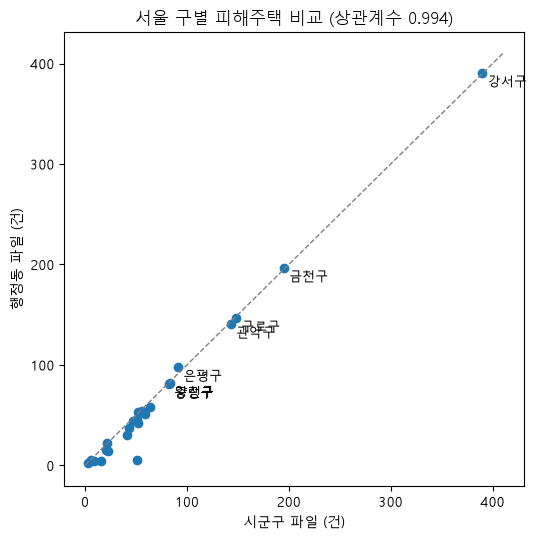

In [8]:
seoul = pd.read_csv(P / "seoul_dong_monthly.csv")
seoul_codes = master[master["시도"] == "서울"].set_index("시군구")["지역코드"]
seoul["지역코드"] = seoul["시군구"].map(seoul_codes)

s_dong = seoul[seoul["연도"] <= 2025].groupby("지역코드")["피해건수"].sum()
s_sgg = merged.set_index("지역코드").loc[s_dong.index, "피해주택_누적"]
names = master.set_index("지역코드").loc[s_dong.index, "시군구"]

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(s_sgg, s_dong)
for x, y, n in zip(s_sgg, s_dong, names):
    if x > 80:
        ax.annotate(n, (x, y), xytext=(4, -10), textcoords="offset points", fontsize=9)
lim = max(s_sgg.max(), s_dong.max()) * 1.05
ax.plot([0, lim], [0, lim], "--", color="gray", linewidth=1)   # 완전히 같으면 이 선 위
ax.set_xlabel("시군구 파일 (건)")
ax.set_ylabel("행정동 파일 (건)")
ax.set_title(f"서울 구별 피해주택 비교 (상관계수 {s_dong.corr(s_sgg):.3f})")
plt.tight_layout()
plt.show()

상관계수 0.99 이상 → 두 파일의 구별 분포가 거의 같다.
행정동 파일 합계가 조금 작은 것은 집계 시점·주소 기준 차이로 보인다(논문에 한계로 언급).

## 7. 저장

In [9]:
merged.to_csv(P / "region_merged.csv", index=False, encoding="utf-8-sig")
seoul.to_csv(P / "seoul_dong_monthly.csv", index=False, encoding="utf-8-sig")
print("저장 완료: region_merged.csv", merged.shape)

저장 완료: region_merged.csv (256, 10)


## 정리

| 문제 | 해결 | 결과 |
|---|---|---|
| 광역시 표기(`서울시`↔`서울`) | METRO 표로 변환 | |
| 도 이름 없는 일반구(`수원시 장안구`) | `수원장안구`로 붙이고 이름으로 찾기 | |
| 세종·제주 시군구 빈칸, `선안시` 오타 | WHOLE_CITY, TYPO 표 | |
| 원본의 시도 오기(가평·남원·익산) | 전국 유일 이름으로 자동 교정 | 못 찾은 행 **0개**, 합계 4,392건 유지 |

> 전월세 실거래가(01b) 수집이 끝나면 `02_merge.py`를 다시 실행해 전세 계약 수를 합친다.